# 03 — Softmax Regression

Khảo sát learning rate/L2, chọn cấu hình bằng validation, đối chiếu sklearn và đánh giá cuối. Phần cài đặt nằm ở `src/models/softmax.py`; lý thuyết chi tiết trình bày trong report. Chạy từ thư mục gốc đồ án hoặc `notebooks/`.


## 1. Import và cấu hình


In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, log_loss
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / 'results' / 'softmax'
OUTPUT.mkdir(parents=True, exist_ok=True)
from src.data import load_prepared_mnist
from src.models.softmax import SoftmaxRegression
print('scikit-learn:', sklearn.__version__)


scikit-learn: 1.9.1


## 2. Nạp dữ liệu và chia tập

Dùng 50.000 train / 10.000 validation / 10.000 test, seed 42. Pixel đã chia 255 và làm phẳng trong `data.py`; nhãn nguyên 0–9.


In [2]:
SEED = 42
X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)

print('Train:', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test:', X_test.shape, y_test.shape)
del X_all
print('Miền pixel:', X_train.min(), X_train.max())
EPOCHS, BATCH_SIZE = 100, 256
BASE_L2 = 1 / len(X_train)


Train: (50000, 784) (50000,)
Validation: (10000, 784) (10000,)
Test: (10000, 784) (10000,)
Miền pixel: 0.0 1.0


## 3. Hàm hỗ trợ thí nghiệm

Giữ ba hàm dùng lại để tính độ đo, chạy khảo sát và vẽ đường CE. Mỗi cấu hình chạy đủ 100 epoch; mô hình cuối được khôi phục về checkpoint có validation CE thấp nhất. Chọn siêu tham số bằng **F1 macro**, CE phá hòa.


In [3]:
def metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, average='macro', zero_division=0)
    return dict(accuracy=accuracy_score(y, pred), precision_macro=precision,
                recall_macro=recall, f1_macro=f1)

def experiment(values, parameter, learning_rate=0.1, l2=BASE_L2):
    models, rows = {}, []
    for value in values:
        params = dict(learning_rate=learning_rate, l2=l2)
        params[parameter] = value
        model = SoftmaxRegression(**params, epochs=EPOCHS, batch_size=BATCH_SIZE,
                                 random_state=SEED, patience=None, verbose=False)
        t0 = time.perf_counter()
        model.fit(X_train, y_train, X_val, y_val)
        seconds = time.perf_counter() - t0
        p = model.predict_proba(X_val)
        models[value] = model
        rows.append({parameter: value, **metrics(y_val, p.argmax(1)),
            'val_CE': log_loss(y_val, p, labels=np.arange(10)),
            'train_accuracy': model.score(X_train, y_train),
            'weight_norm': np.linalg.norm(model.W_),
            'best_epoch': model.best_epoch_, 'fit_seconds': seconds})
        print(f'{parameter}={value:g}: val F1={rows[-1]["f1_macro"]:.4f}', flush=True)
    return models, pd.DataFrame(rows)

def plot_experiment(models, parameter):
    fig, ax = plt.subplots(figsize=(8, 4))
    for value, model in models.items():
        loss = model.history_['val_loss']
        ax.plot(range(1, len(loss) + 1), loss, label=f'{parameter}={value:g}')
    ax.set(xlabel='Epoch', ylabel='Validation cross-entropy', title=f'Ảnh hưởng của {parameter}')
    ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT / f'survey_{parameter}.png', dpi=300)
    plt.show()

# Mỗi cấu hình chạy đủ EPOCHS, rồi khôi phục checkpoint có validation CE thấp nhất.
# Chọn siêu tham số theo F1 macro, CE phá hòa; test không tham gia chọn.


## 4. Khảo sát learning rate


learning_rate=0.001: val F1=0.8742
learning_rate=0.01: val F1=0.9078
learning_rate=0.1: val F1=0.9202
learning_rate=0.5: val F1=0.9218
learning_rate=1: val F1=0.9216


,learning_rate,accuracy,precision_macro,recall_macro,f1_macro,val_CE,train_accuracy,weight_norm,best_epoch,fit_seconds
0,0.001,0.8760,0.87565,0.87399,0.87418,0.49735,0.87684,4.391210,100,10.93233
1,0.010,0.9087,0.90816,0.90767,0.90775,0.32657,0.91256,8.472590,100,10.82385
2,0.100,0.9211,0.92025,0.92023,0.92016,0.28524,0.92950,14.866900,96,10.90963
3,0.500,0.9228,0.92196,0.92187,0.92180,0.28371,0.93330,20.224739,58,11.92331
4,1.000,0.9227,0.92197,0.92167,0.92165,0.28894,0.93432,24.833570,58,11.25555


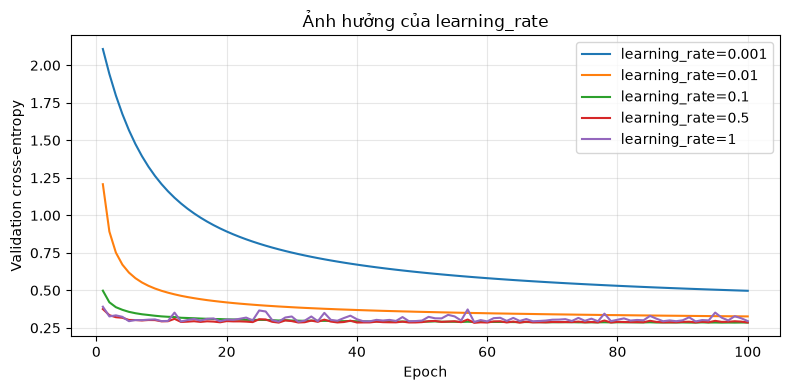

Learning rate được chọn: 0.5


In [4]:
lr_models, lr_results = experiment([0.001, 0.01, 0.1, 0.5, 1.0], 'learning_rate')
display(lr_results.round(5))
plot_experiment(lr_models, 'learning_rate')
best_lr = float(lr_results.loc[lr_results.sort_values(['f1_macro', 'val_CE'], ascending=[False, True]).index[0], 'learning_rate'])
print('Learning rate được chọn:', best_lr)

**Nhận xét lần chạy đính kèm:** learning rate 0,001 giảm CE chậm trong 100 epoch; giá trị 1,0 dao động mạnh hơn 0,5. Giá trị 0,5 được chọn theo F1 macro validation. Kết luận áp dụng cho lưới và ngân sách epoch hiện tại.


## 5. Khảo sát L2 và chọn cấu hình

Giữ learning rate đã chọn, thay đổi L2 và tái sử dụng baseline. Đây là tìm kiếm tuần tự, không khảo sát mọi tổ hợp learning rate × L2.


l2=0: val F1=0.9213
l2=1e-05: val F1=0.9216
l2=0.0001: val F1=0.9216
l2=0.001: val F1=0.9161


,l2,accuracy,precision_macro,recall_macro,f1_macro,val_CE,train_accuracy,weight_norm,best_epoch,fit_seconds
0,0.00000,0.9223,0.92142,0.92137,0.92129,0.28428,0.93392,20.963650,58,11.00438
1,0.00001,0.9226,0.92174,0.92166,0.92159,0.28397,0.93348,20.585711,58,11.28963
4,0.00002,0.9228,0.92196,0.92187,0.92180,0.28371,0.93330,20.224739,58,11.92331
2,0.00010,0.9226,0.92181,0.92166,0.92162,0.28296,0.93234,17.846670,58,11.19019
3,0.00100,0.9171,0.91647,0.91608,0.91608,0.30113,0.92154,10.314260,58,13.90405


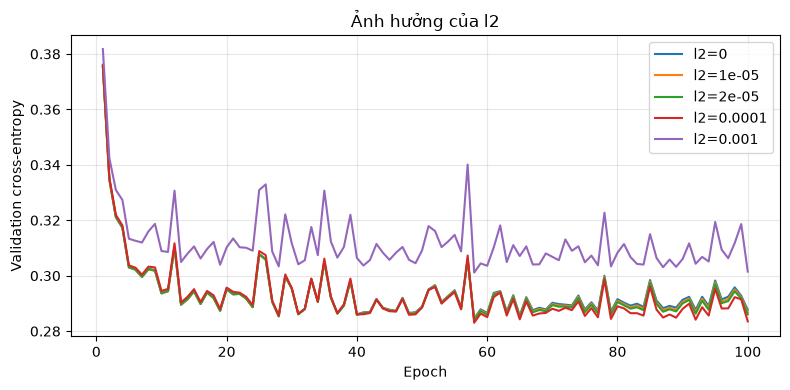

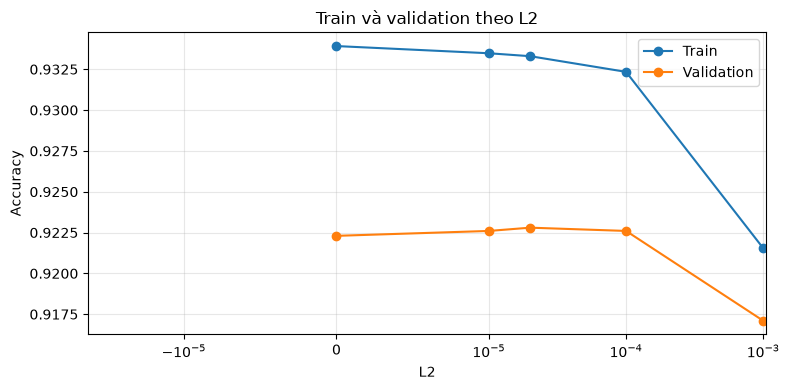

Chọn lr=0.5, L2=2e-05, checkpoint=58
Tổng thời gian tìm kiếm: 103.23s


In [5]:
# Tái sử dụng cấu hình L2 baseline đã chạy ở thí nghiệm learning rate.
l2_models, l2_results = experiment([0, 1e-5, 1e-4, 1e-3], 'l2', learning_rate=best_lr)
l2_models[BASE_L2] = lr_models[best_lr]
baseline = lr_results.loc[[lr_results.sort_values(['f1_macro', 'val_CE'], ascending=[False, True]).index[0]]].drop(columns='learning_rate').copy()
baseline['l2'] = BASE_L2
l2_results = pd.concat([l2_results, baseline], ignore_index=True).sort_values('l2')
display(l2_results.round(5))
plot_experiment(dict(sorted(l2_models.items())), 'l2')

ax = l2_results.plot(x='l2', y=['train_accuracy', 'accuracy'], marker='o', figsize=(8, 4))
ax.set_xscale('symlog', linthresh=1e-5)
ax.set(xlabel='L2', ylabel='Accuracy', title='Train và validation theo L2')
ax.legend(['Train', 'Validation']); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUTPUT / 'l2_accuracy.png', dpi=300); plt.show()

best_row = l2_results.sort_values(['f1_macro', 'val_CE'], ascending=[False, True]).iloc[0]
best_l2 = float(best_row['l2'])
manual, manual_time = l2_models[best_l2], float(best_row['fit_seconds'])
search_seconds = lr_results.fit_seconds.sum() + l2_results.loc[l2_results.l2 != BASE_L2, 'fit_seconds'].sum()
print(f'Chọn lr={best_lr:g}, L2={best_l2:g}, checkpoint={manual.best_epoch_}')
print(f'Tổng thời gian tìm kiếm: {search_seconds:.2f}s')
# Đây là tìm kiếm tuần tự LR rồi L2, không phải tìm mọi tổ hợp LR × L2.

**Nhận xét lần chạy đính kèm:** L2 = 2e-5 (baseline) cho F1 macro validation cao nhất trong các giá trị đã thử; L2 = 1e-3 cho điểm thấp hơn. Giữ learning rate 0,5 và L2 = 2e-5 cho đánh giá cuối; không thay cấu hình sau khi xem test.


## 6. Đường cong huấn luyện

Loss hiển thị là **cross-entropy không gồm L2**; gradient huấn luyện có thêm phạt L2. Đường cong ghi toàn bộ 100 epoch, còn trọng số được khôi phục tại checkpoint đã chọn.


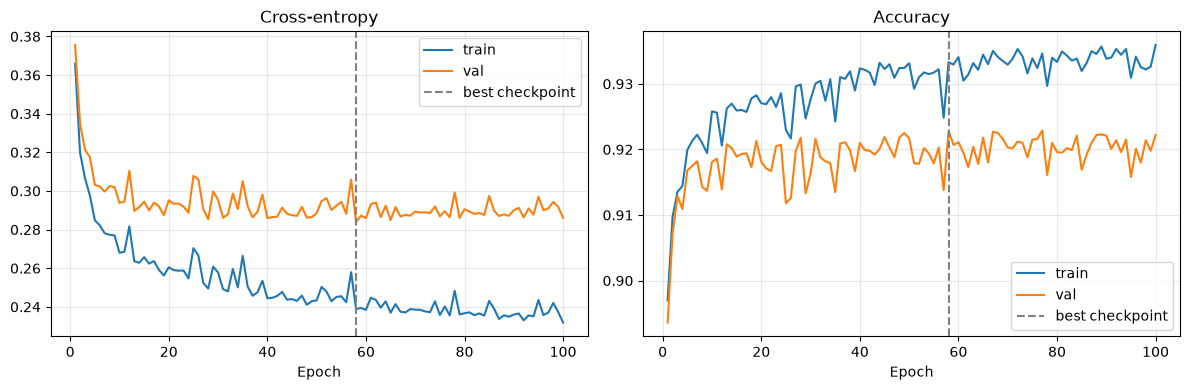

In [6]:
h = manual.history_
epochs = np.arange(1, len(h['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ['train', 'val']:
    axes[0].plot(epochs, h[f'{split}_loss'], label=split)
    axes[1].plot(epochs, h[f'{split}_accuracy'], label=split)
for ax, title in zip(axes, ['Cross-entropy', 'Accuracy']):
    ax.axvline(manual.best_epoch_, color='gray', linestyle='--', label='best checkpoint')
    ax.set(xlabel='Epoch', title=title)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(OUTPUT / 'training_curves.png', dpi=300)
plt.show()


**Nhận xét:** vạch dọc đánh dấu checkpoint được chọn theo CE, không nhất thiết trùng epoch có accuracy cao nhất.


## 7. Đối chiếu sklearn

Với objective `mean CE + l2/2 * ||W||²`, dùng `C = 1/(l2 * n_train)`; không phạt bias. Hai cài đặt khác thuật toán tối ưu và điều kiện dừng nên không yêu cầu trọng số hoặc dự đoán trùng hoàn toàn. Giữ cảnh báo hội tụ để đánh giá kết quả.


In [7]:
# mean CE + L2/2 * ||W||²; không phạt bias, không dùng trọng số mẫu/lớp.
# SGD và L-BFGS khác optimizer/điều kiện dừng, không suy ra hiệu quả cài đặt từ thời gian.
C = 1 / (best_l2 * len(X_train)) if best_l2 > 0 else np.inf
reference = LogisticRegression(C=C, solver='lbfgs', max_iter=300, tol=1e-4)
t0 = time.perf_counter()
reference.fit(X_train, y_train)  # Giữ cảnh báo nếu chưa hội tụ.
reference_time = time.perf_counter() - t0
print(f'C={C:g}; fit={reference_time:.2f}s; iterations={reference.n_iter_}')

C=1; fit=333.01s; iterations=[259]


## 8. Đánh giá trên train, validation và test

Giữ mô hình fit trên 50.000 train. Test chỉ được đánh giá sau khi chốt cấu hình. Vẽ confusion matrix của mô hình tự viết trên ba tập; bảng độ đo có cả hai cài đặt. Thời gian đo một lần, không phải benchmark; thời gian SGD và L-BFGS không trực tiếp phản ánh chất lượng cài đặt.


,model,split,accuracy,precision_macro,recall_macro,f1_macro,fit_seconds,predict_seconds
0,Softmax tự viết,Train,0.9333,0.9325,0.9323,0.9323,11.9233,0.0248
1,Softmax tự viết,Validation,0.9228,0.9220,0.9219,0.9218,11.9233,0.0057
2,Softmax tự viết,Test,0.9253,0.9244,0.9241,0.9241,11.9233,0.0054
3,Softmax sklearn,Train,0.9402,0.9395,0.9394,0.9394,333.0140,0.0460
4,Softmax sklearn,Validation,0.9217,0.9208,0.9207,0.9207,333.0140,0.0099
5,Softmax sklearn,Test,0.9241,0.9232,0.9230,0.9230,333.0140,0.0105


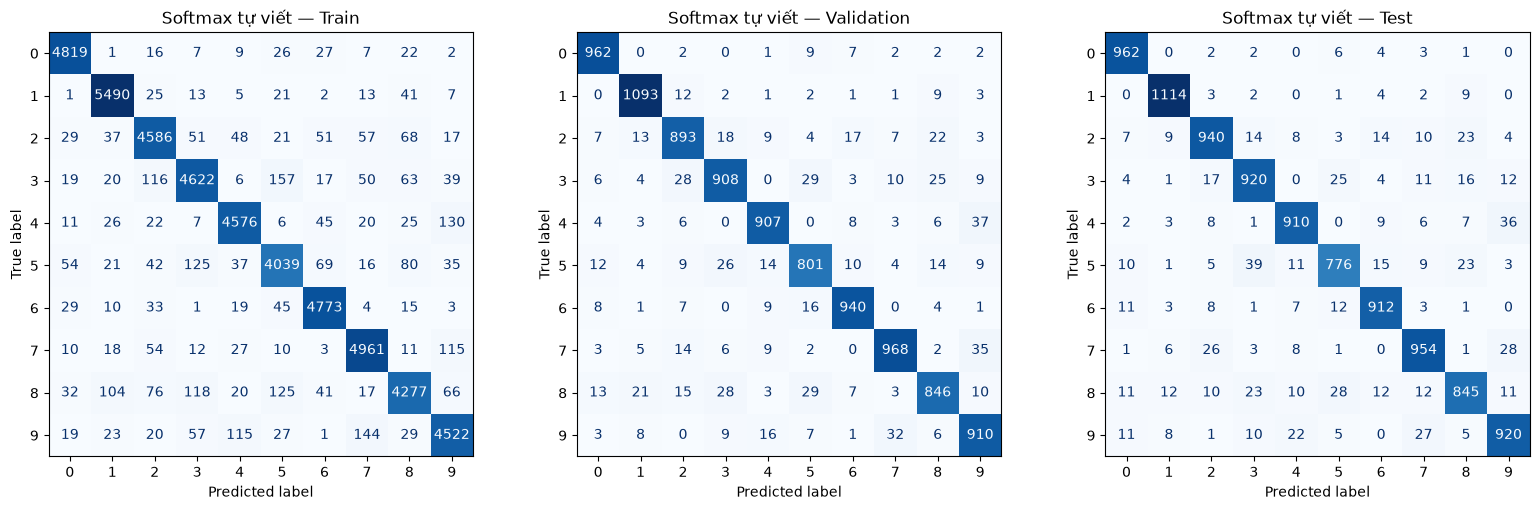

Test accuracy=92.53%; F1 macro=0.9241


In [8]:
models = {'Softmax tự viết': manual, 'Softmax sklearn': reference}
datasets = {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}
rows, predictions = [], {}
for name, model in models.items():
    for split, (X, y) in datasets.items():
        t0 = time.perf_counter()
        pred = model.predict_proba(X).argmax(1)
        seconds = time.perf_counter() - t0
        predictions[name, split] = pred
        rows.append({'model': name, 'split': split, **metrics(y, pred),
            'fit_seconds': manual_time if name == 'Softmax tự viết' else reference_time,
            'predict_seconds': seconds})
results = pd.DataFrame(rows)
display(results.round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (split, (_, y)) in zip(axes, datasets.items()):
    ConfusionMatrixDisplay.from_predictions(y, predictions['Softmax tự viết', split], labels=np.arange(10),
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'Softmax tự viết — {split}')
fig.tight_layout(); fig.savefig(OUTPUT / 'confusion_matrices.png', dpi=300); plt.show()
manual_test = results.query("model == 'Softmax tự viết' and split == 'Test'").iloc[0]
print(f'Test accuracy={manual_test.accuracy:.2%}; F1 macro={manual_test.f1_macro:.4f}')


**Nhận xét:** train là in-sample, validation đã dùng để chọn cấu hình. Dùng test làm kết quả cuối; không kết luận overfitting chỉ từ một chênh lệch nhỏ giữa các tập.


## 9. Trọng số và phân tích lỗi

Bản đồ trọng số thể hiện đóng góp tuyến tính của pixel vào logit từng lớp, không phải ảnh mẫu hay giải thích nhân quả. Lấy ngẫu nhiên tối đa 8 ảnh sai với seed cố định.


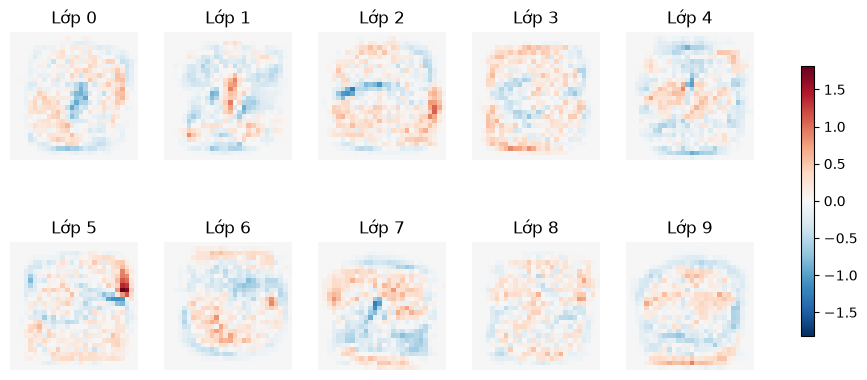

Độ đo theo chữ số trên test:


,precision,recall,f1-score,support
0,0.9441,0.9816,0.9625,980.0
1,0.9628,0.9815,0.9721,1135.0
2,0.9216,0.9109,0.9162,1032.0
3,0.9064,0.9109,0.9086,1010.0
4,0.9324,0.9267,0.9295,982.0
5,0.9055,0.8700,0.8874,892.0
6,0.9363,0.9520,0.9441,958.0
7,0.9200,0.9280,0.9240,1028.0
8,0.9076,0.8676,0.8871,974.0
9,0.9073,0.9118,0.9095,1009.0


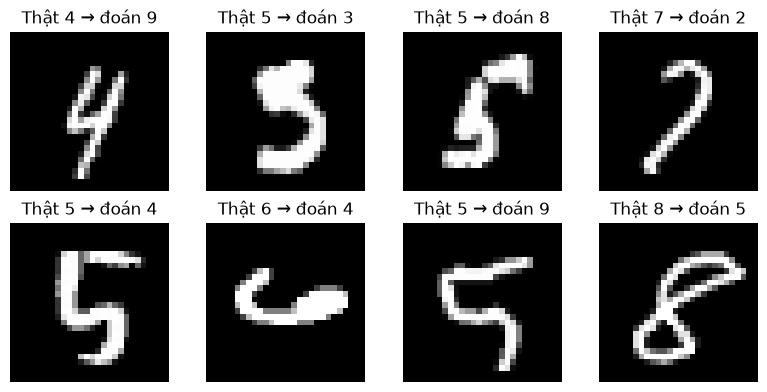

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
v = abs(manual.W_).max()
for k, ax in enumerate(axes.flat):
    im = ax.imshow(manual.W_[:, k].reshape(28, 28), cmap='RdBu_r', vmin=-v, vmax=v)
    ax.set_title(f'Lớp {k}'); ax.axis('off')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7)
fig.savefig(OUTPUT / 'weight_maps.png', dpi=300, bbox_inches='tight')
plt.show()
pred = predictions['Softmax tự viết', 'Test']
report = pd.DataFrame(classification_report(y_test, pred, output_dict=True, zero_division=0)).T
print('Độ đo theo chữ số trên test:')
display(report.loc[[str(k) for k in range(10)]].round(4))
wrong = np.flatnonzero(pred != y_test)
wrong = np.random.default_rng(SEED).choice(wrong, min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax in axes.flat: ax.axis('off')
for ax, i in zip(axes.flat, wrong):
    ax.imshow(X_test[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Thật {y_test[i]} → đoán {pred[i]}')
fig.tight_layout(); fig.savefig(OUTPUT / 'error_examples.png', dpi=300); plt.show()

**Nhận xét:** bảng theo lớp và ảnh sai hỗ trợ phân tích nhầm lẫn. Softmax chỉ học ranh giới tuyến tính trên pixel; so sánh với MLP/Ensemble cần cùng split và giao thức.


## 10. Xuất kết quả

Lưu bảng CSV, cấu hình, trọng số và hình PNG 300 dpi để dùng cho report/slide. `fit_seconds` là thời gian chạy riêng cấu hình cuối, `search_seconds` là tổng thời gian tìm kiếm; không cộng lặp thời gian fit qua ba split. Chạy lại ghi đè file cùng tên.


In [10]:
for name, table in {'metrics': results, 'learning_rate': lr_results, 'l2': l2_results,
                    'history': pd.DataFrame(manual.history_)}.items():
    table.to_csv(OUTPUT / f'{name}.csv', index=False)
results.query("model == 'Softmax tự viết' and split == 'Test'").to_csv(OUTPUT / 'comparison.csv', index=False)
report.to_csv(OUTPUT / 'classification_report_test.csv')
for split, (_, y) in datasets.items():
    cm = confusion_matrix(y, predictions['Softmax tự viết', split], labels=np.arange(10))
    pd.DataFrame(cm, index=np.arange(10), columns=np.arange(10)).to_csv(OUTPUT / f'confusion_{split.lower()}.csv', index_label='true_digit')
np.savez_compressed(OUTPUT / 'manual_weights.npz', W=manual.W_, b=manual.b_)
config = dict(learning_rate=best_lr, l2=best_l2, epochs=EPOCHS, batch_size=BATCH_SIZE,
              seed=SEED, best_epoch=int(manual.best_epoch_), search_seconds=float(search_seconds),
              selection='F1 macro, validation CE pha hoa', sklearn_C=float(C), sklearn_version=sklearn.__version__,
              train_samples=len(y_train), validation_samples=len(y_val), test_samples=len(y_test))
(OUTPUT / 'config.json').write_text(json.dumps(config, indent=2), encoding='utf-8')
print('Số tham số:', manual.W_.size + manual.b_.size)
print('Đã lưu:', OUTPUT)

Số tham số: 7850
Đã lưu: d:\Nhận dạng mẫu\mnist\results\softmax
